In [2]:
# ============================================================
# TestData 1例でDVFスケールとWavelet再構成過程を診断
# 学習は行わない
# ============================================================

import math
import re
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import voxelmorph as vxm

backend:pytorch
Pytorch


In [3]:
# ------------------------------------------------------------
# Settings
# ------------------------------------------------------------

device = torch.device(
    "cuda:0" if torch.cuda.is_available() else "cpu"
)

FULL_SIZE = (128, 256, 256)
LOW_SIZE = (64, 128, 128)
COARSE_SIZE = (8, 16, 16)

# 80k Curriculum完了時のcheckpointを指定
CURRICULUM_80K_PATH = Path(
    r"D:\Saito\fullres_trilinear_short_20k_10k\model_fullres_trilinear_curriculum_20k_final.pth"
)

# TestDataのpairを指定
TEST_PAIR_DIR = Path(
    r"D:\Saito\Data\TestData\pair1"
)

OUTPUT_DIR = Path(
    "dvf_wavelet_diagnostic_pair1"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# 人工的な正解DVFの最大変位量（full-resolution voxel単位）
ARTIFICIAL_SHIFT_VOX = 20.0

VIEW_Z_FULL = 64
VIEW_Z_LOW = 32

print("Device:", device)
print("Checkpoint:", CURRICULUM_80K_PATH)
print("Test pair:", TEST_PAIR_DIR)


Device: cuda:0
Checkpoint: D:\Saito\fullres_trilinear_short_20k_10k\model_fullres_trilinear_curriculum_20k_final.pth
Test pair: D:\Saito\Data\TestData\pair1


In [4]:

# ------------------------------------------------------------
# NPZ load
# ------------------------------------------------------------

def load_npz_volume(path):
    with np.load(path) as archive:
        if "Train" in archive:
            volume = archive["Train"]
        else:
            first_key = archive.files[0]
            volume = archive[first_key]

    volume = np.asarray(volume, dtype=np.float32)
    volume = np.squeeze(volume)

    # (256, 256, 128) -> (128, 256, 256)
    if volume.shape == (256, 256, 128):
        volume = np.transpose(volume, (2, 0, 1))

    if volume.shape != FULL_SIZE:
        raise ValueError(
            f"予期しない画像サイズ: {volume.shape}, "
            f"期待値: {FULL_SIZE}"
        )

    return volume


def natural_key(path):
    parts = re.split(r"(\d+)", path.name)
    return [
        int(part) if part.isdigit() else part.lower()
        for part in parts
    ]


def find_moving_file(pair_dir):
    files = sorted(
        pair_dir.glob("*.npz"),
        key=natural_key,
    )

    if len(files) != 2:
        raise RuntimeError(
            f"{pair_dir} にnpzが2枚必要です: {files}"
        )

    # registered / moving / _A_ をMovingとして優先
    for path in files:
        name = path.name.lower()
        if (
            "registered" in name
            or "moving" in name
            or "_a_" in name
        ):
            return path

    return files[0]



In [5]:

# ------------------------------------------------------------
# Haar Analysis
# 学習時と同じ: analysis -> ::2
# ------------------------------------------------------------

class Haar3DAnalysisOnly(nn.Module):
    def __init__(self):
        super().__init__()

        h_low = torch.tensor(
            [1.0, 1.0],
            dtype=torch.float32,
        ) / math.sqrt(2.0)

        h_high = torch.tensor(
            [1.0, -1.0],
            dtype=torch.float32,
        ) / math.sqrt(2.0)

        filters = []
        names = []

        for z_name, z_filter in zip(
            ["L", "H"],
            [h_low, h_high],
        ):
            for y_name, y_filter in zip(
                ["L", "H"],
                [h_low, h_high],
            ):
                for x_name, x_filter in zip(
                    ["L", "H"],
                    [h_low, h_high],
                ):
                    kernel = (
                        z_filter[:, None, None]
                        * y_filter[None, :, None]
                        * x_filter[None, None, :]
                    )
                    filters.append(kernel)
                    names.append(
                        z_name + y_name + x_name
                    )

        self.register_buffer(
            "weight",
            torch.stack(filters, dim=0).unsqueeze(1),
        )
        self.names = names

    def forward(self, image):
        image = F.pad(
            image,
            (0, 1, 0, 1, 0, 1),
        )

        coefficients_full = F.conv3d(
            image,
            self.weight,
            stride=1,
            padding=0,
        )

        return coefficients_full[
            :,
            :,
            ::2,
            ::2,
            ::2,
        ]


analysis = Haar3DAnalysisOnly().to(device)
BAND_NAMES = analysis.names


In [6]:
# ------------------------------------------------------------
# Haar Synthesis
# ------------------------------------------------------------

def make_3d_filter(z_filter, y_filter, x_filter):
    return (
        z_filter[:, None, None]
        * y_filter[None, :, None]
        * x_filter[None, None, :]
    )


def create_synthesis_filters():
    h_low = torch.tensor(
        [1.0, 1.0],
        dtype=torch.float32,
        device=device,
    ) / math.sqrt(2.0)

    h_high = torch.tensor(
        [1.0, -1.0],
        dtype=torch.float32,
        device=device,
    ) / math.sqrt(2.0)

    filters = torch.stack(
        [
            make_3d_filter(h_low, h_low, h_low),
            make_3d_filter(h_low, h_low, h_high),
            make_3d_filter(h_low, h_high, h_low),
            make_3d_filter(h_low, h_high, h_high),
            make_3d_filter(h_high, h_low, h_low),
            make_3d_filter(h_high, h_low, h_high),
            make_3d_filter(h_high, h_high, h_low),
            make_3d_filter(h_high, h_high, h_high),
        ],
        dim=0,
    )

    # conv3dでのsynthesis用に反転
    return torch.flip(
        filters,
        dims=[1, 2, 3],
    ).unsqueeze(1)


SYNTHESIS_FILTERS = create_synthesis_filters()


def up_sampling_3d(coeff_low):
    """
    (B, 8, 64, 128, 128)
    -> (B, 8, 128, 256, 256)

    偶数座標へ係数を置き、残りはゼロ。
    """
    batch, channels, depth, height, width = coeff_low.shape

    coeff_up = torch.zeros(
        batch,
        channels,
        depth * 2,
        height * 2,
        width * 2,
        dtype=coeff_low.dtype,
        device=coeff_low.device,
    )

    coeff_up[:, :, ::2, ::2, ::2] = coeff_low

    return coeff_up


def synthesis_filter_3d(coeff_up):
    """
    coeff_up: (B, 8, 128, 256, 256)

    return:
        reconstructed : (B, 1, 128, 256, 256)
        filtered_bands: (B, 8, 128, 256, 256)
    """
    _, channels, depth, height, width = coeff_up.shape

    filters = SYNTHESIS_FILTERS.to(
        device=coeff_up.device,
        dtype=coeff_up.dtype,
    )

    filtered_bands = F.conv3d(
        coeff_up,
        filters,
        stride=1,
        padding=1,
        groups=channels,
    )

    filtered_bands = filtered_bands[
        :,
        :,
        :depth,
        :height,
        :width,
    ]

    reconstructed = torch.sum(
        filtered_bands,
        dim=1,
        keepdim=True,
    )

    return reconstructed, filtered_bands



In [7]:
# ------------------------------------------------------------
# DVF and spatial transformers
# ------------------------------------------------------------

transformer_low_linear = vxm.layers.SpatialTransformer(
    LOW_SIZE,
    mode="bilinear",
).to(device)

transformer_low_nearest = vxm.layers.SpatialTransformer(
    LOW_SIZE,
    mode="nearest",
).to(device)

def warp_wavelet_highfreq_nearest(moving_w, flow_low):
    warped_bands = []

    for channel in range(8):
        if channel == 0:
            warped = transformer_low_linear(
                moving_w[:, channel:channel + 1],
                flow_low,
            )
        else:
            warped = transformer_low_nearest(
                moving_w[:, channel:channel + 1],
                flow_low,
            )

        warped_bands.append(warped)

    return torch.cat(warped_bands, dim=1)

transformer_full = vxm.layers.SpatialTransformer(
    FULL_SIZE
).to(device)


def low_dvf_to_full_dvf(flow_low):
    """
    low voxel単位 -> full voxel単位。
    解像度が2倍なので移動量も2倍。
    """
    return F.interpolate(
        flow_low.float(),
        size=FULL_SIZE,
        mode="trilinear",
        align_corners=False,
    ) * 2.0


def full_dvf_to_low_dvf(flow_full):
    """
    full voxel単位 -> low voxel単位。
    解像度が1/2なので移動量も1/2。
    """
    return F.interpolate(
        flow_full.float(),
        size=LOW_SIZE,
        mode="trilinear",
        align_corners=False,
    ) * 0.5


def gaussian_smooth_3d(flow, sigma=2.0):
    radius = max(1, int(math.ceil(3.0 * sigma)))

    coordinate = torch.arange(
        -radius,
        radius + 1,
        device=flow.device,
        dtype=flow.dtype,
    )

    kernel_1d = torch.exp(
        -(coordinate ** 2) / (2.0 * sigma ** 2)
    )
    kernel_1d = kernel_1d / kernel_1d.sum()

    channels = flow.shape[1]

    kernel_z = kernel_1d.view(
        1, 1, -1, 1, 1
    ).repeat(channels, 1, 1, 1, 1)

    kernel_y = kernel_1d.view(
        1, 1, 1, -1, 1
    ).repeat(channels, 1, 1, 1, 1)

    kernel_x = kernel_1d.view(
        1, 1, 1, 1, -1
    ).repeat(channels, 1, 1, 1, 1)

    flow = F.conv3d(
        flow,
        kernel_z,
        padding=(radius, 0, 0),
        groups=channels,
    )

    flow = F.conv3d(
        flow,
        kernel_y,
        padding=(0, radius, 0),
        groups=channels,
    )

    flow = F.conv3d(
        flow,
        kernel_x,
        padding=(0, 0, radius),
        groups=channels,
    )

    return flow


def make_artificial_true_dvf(batch_size, shift):
    """
    Curriculumと同様にfull-resolution正解DVFを作る。
    """
    coarse_flow = (
        torch.rand(
            batch_size,
            3,
            *COARSE_SIZE,
            device=device,
        ) * 2.0 - 1.0
    ) * shift

    coarse_flow = gaussian_smooth_3d(
        coarse_flow,
        sigma=2.0,
    )

    flow_full = F.interpolate(
        coarse_flow,
        size=FULL_SIZE,
        mode="trilinear",
        align_corners=False,
    )

    flow_low = full_dvf_to_low_dvf(flow_full)

    return flow_full, flow_low


def flow_statistics(name, flow):
    magnitude = torch.linalg.vector_norm(
        flow.float(),
        dim=1,
    )

    print(
        f"{name}\n"
        f"  shape        : {tuple(flow.shape)}\n"
        f"  abs mean     : {flow.abs().mean().item():.6f}\n"
        f"  magnitude μ  : {magnitude.mean().item():.6f} voxel\n"
        f"  magnitude max: {magnitude.max().item():.6f} voxel\n"
        f"  min / max    : "
        f"{flow.min().item():.6f} / "
        f"{flow.max().item():.6f}"
    )

c:\Users\user\anaconda3\envs\nn\lib\site-packages\torch\functional.py:507: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at C:\cb\pytorch_1000000000000\work\aten\src\ATen\native\TensorShape.cpp:3550.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


In [8]:
# ------------------------------------------------------------
# Model and checkpoint
# ------------------------------------------------------------

nb_features = [
    [32, 64, 64, 64, 64],
    [64, 64, 64, 64, 64, 32, 16, 16],
]

model = vxm.networks.VxmDense_128_256_256(
    FULL_SIZE,
    nb_features,
    int_steps=0,
).to(device)

if not CURRICULUM_80K_PATH.exists():
    raise FileNotFoundError(
        f"80k checkpointがありません:\n"
        f"{CURRICULUM_80K_PATH}"
    )

try:
    checkpoint = torch.load(
        CURRICULUM_80K_PATH,
        map_location=device,
        weights_only=False,
    )
except TypeError:
    checkpoint = torch.load(
        CURRICULUM_80K_PATH,
        map_location=device,
    )

if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
    state_dict = checkpoint["model_state_dict"]
else:
    state_dict = checkpoint

if any(
    key.startswith("_orig_mod.")
    for key in state_dict
):
    state_dict = {
        key.replace("_orig_mod.", "", 1): value
        for key, value in state_dict.items()
    }

model.load_state_dict(
    state_dict,
    strict=True,
)

model.eval()

print("Model loaded.")



[64, 128, 128]
Model loaded.


In [9]:

# ------------------------------------------------------------
# Visualization helpers
# ------------------------------------------------------------

def show_8_bands(
    bands,
    z_index,
    title,
    output_path,
):
    """
    bands: (1, 8, D, H, W)
    """
    bands_np = bands[0].detach().float().cpu().numpy()
    z_index = min(z_index, bands_np.shape[1] - 1)

    vmax = np.percentile(
        np.abs(bands_np[:, z_index]),
        99,
    )
    vmax = max(float(vmax), 1e-8)

    fig, axes = plt.subplots(
        2,
        4,
        figsize=(16, 8),
        constrained_layout=True,
    )

    for channel, axis in enumerate(axes.ravel()):
        axis.imshow(
            bands_np[channel, z_index],
            cmap="gray",
        )
        axis.set_title(BAND_NAMES[channel])
        axis.axis("off")

    fig.suptitle(title, fontsize=15)
    fig.savefig(
        output_path,
        dpi=180,
        bbox_inches="tight",
    )
    plt.show()
    plt.close(fig)


def show_final_images(
    moving,
    teacher_full,
    teacher_wavelet,
    predicted_wavelet,
    output_path,
):
    z = min(VIEW_Z_FULL, moving.shape[2] - 1)

    images = [
        moving[0, 0, z].cpu().numpy(),
        teacher_full[0, 0, z].cpu().numpy(),
        teacher_wavelet[0, 0, z].cpu().numpy(),
        predicted_wavelet[0, 0, z].cpu().numpy(),
    ]

    titles = [
        "Moving",
        "Teacher: full-DVF STN",
        "Teacher: wavelet STN + synthesis",
        "Predicted-DVF wavelet output",
    ]

    fig, axes = plt.subplots(
        1,
        4,
        figsize=(20, 5),
        constrained_layout=True,
    )

    for axis, image, title in zip(
        axes,
        images,
        titles,
    ):
        axis.imshow(
            image,
            cmap="gray",
        )
        axis.set_title(title)
        axis.axis("off")

    fig.suptitle(
        "Final reconstruction comparison",
        fontsize=15,
    )

    fig.savefig(
        output_path,
        dpi=180,
        bbox_inches="tight",
    )
    plt.show()
    plt.close(fig)


Moving file: registered_masked_A_MIC00197_2018_0428.npz

========== DVF statistics ==========
GT low DVF
  shape        : (1, 3, 64, 128, 128)
  abs mean     : 0.205398
  magnitude μ  : 0.411049 voxel
  magnitude max: 1.063582 voxel
  min / max    : -0.753557 / 0.930084
Predicted low DVF
  shape        : (1, 3, 64, 128, 128)
  abs mean     : 0.233691
  magnitude μ  : 0.463657 voxel
  magnitude max: 1.501239 voxel
  min / max    : -1.396319 / 1.274023
GT full DVF
  shape        : (1, 3, 128, 256, 256)
  abs mean     : 0.410854
  magnitude μ  : 0.822210 voxel
  magnitude max: 2.136216 voxel
  min / max    : -1.513457 / 1.864816
Predicted full DVF
  shape        : (1, 3, 128, 256, 256)
  abs mean     : 0.466625
  magnitude μ  : 0.925806 voxel
  magnitude max: 2.920985 voxel
  min / max    : -2.740492 / 2.488420

========== Error checks ==========
DVF MSE (pred low vs GT low): 0.030880548059940338
Teacher full-STN vs teacher wavelet reconstruction MSE: 0.0005734305595979095
Teacher full-ST

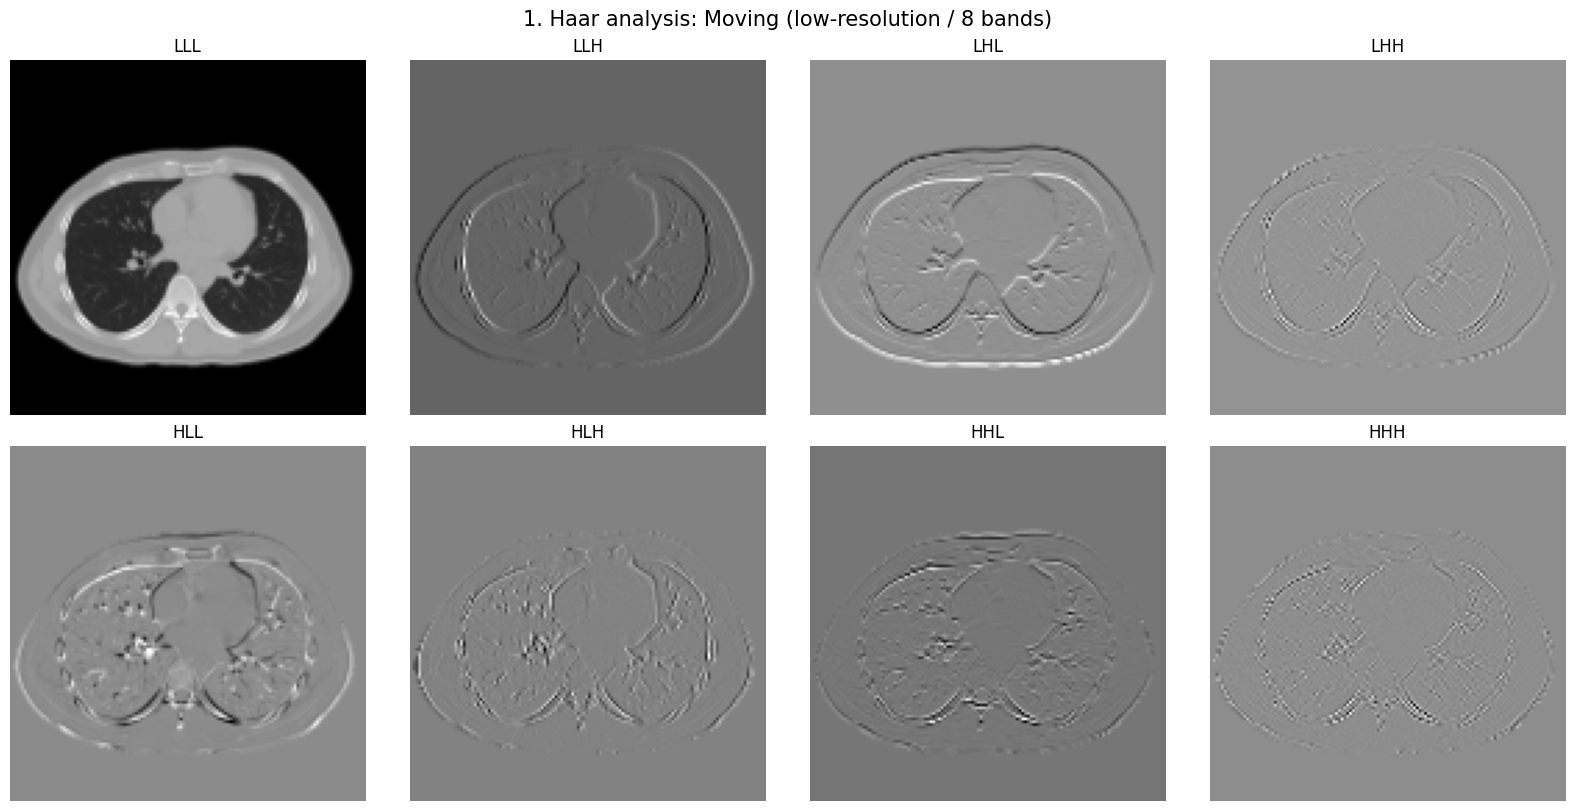

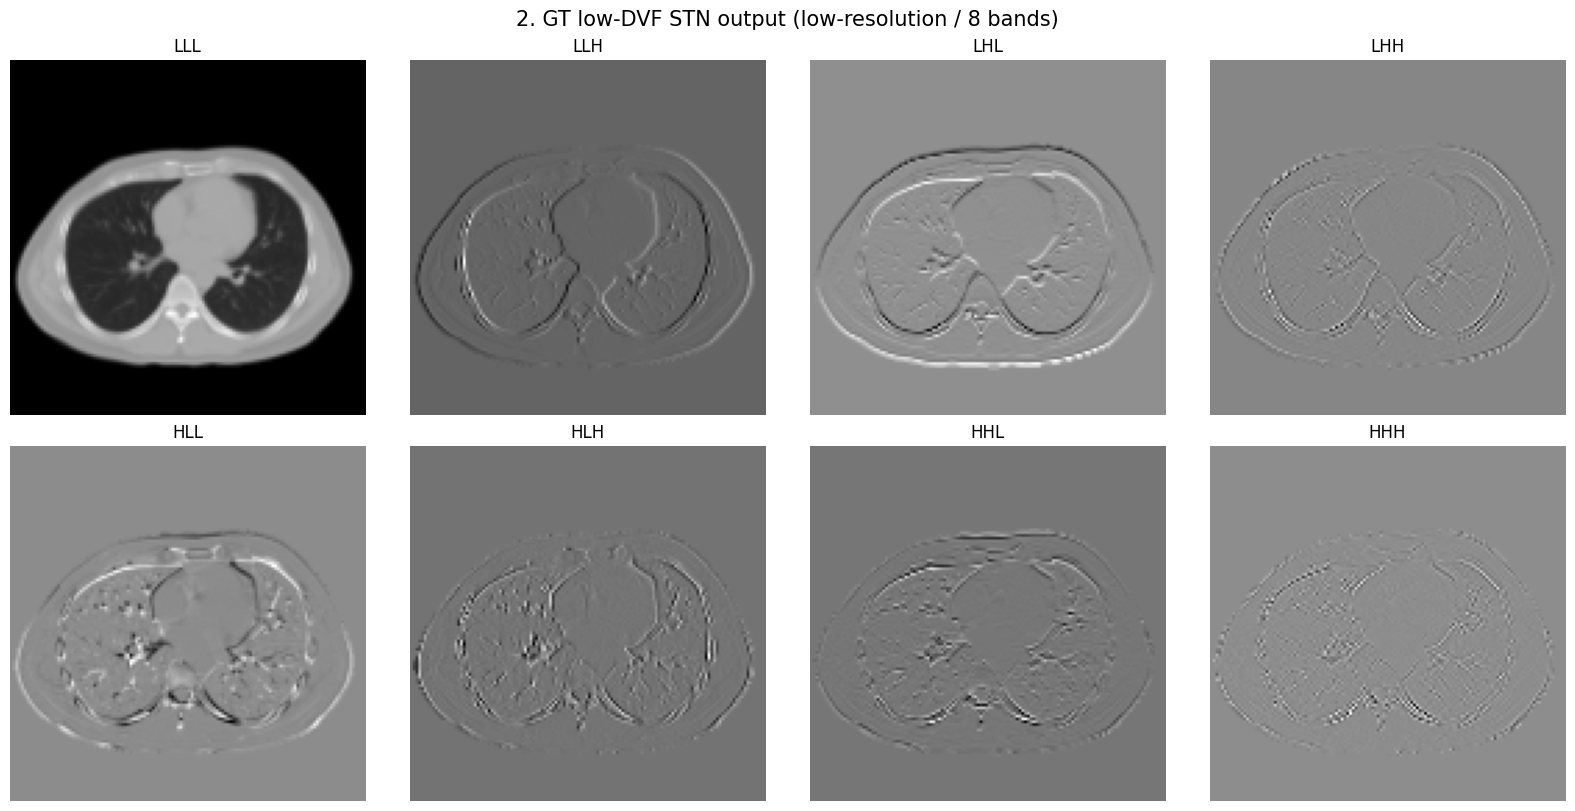

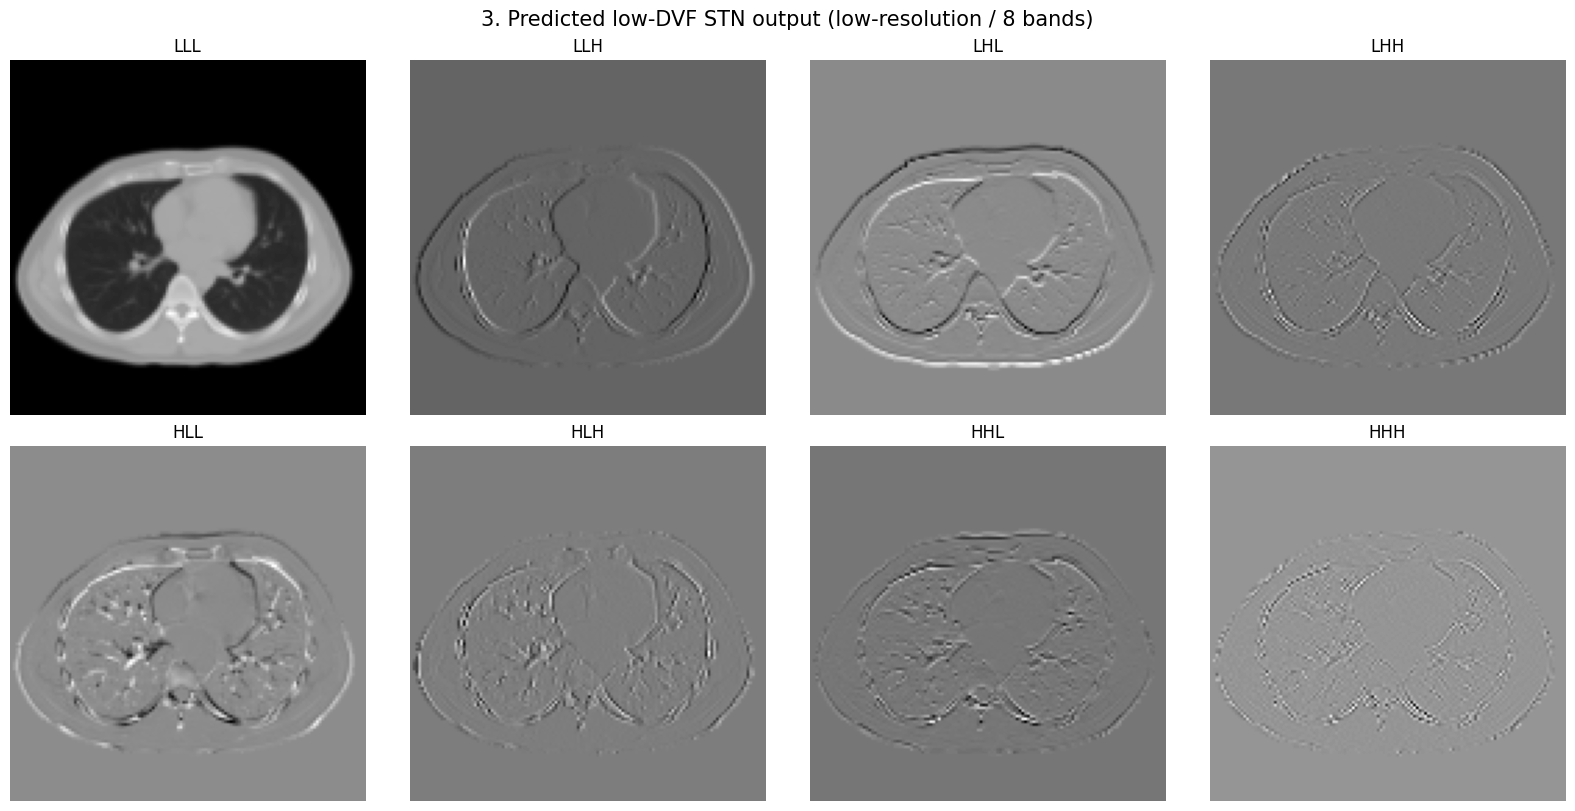

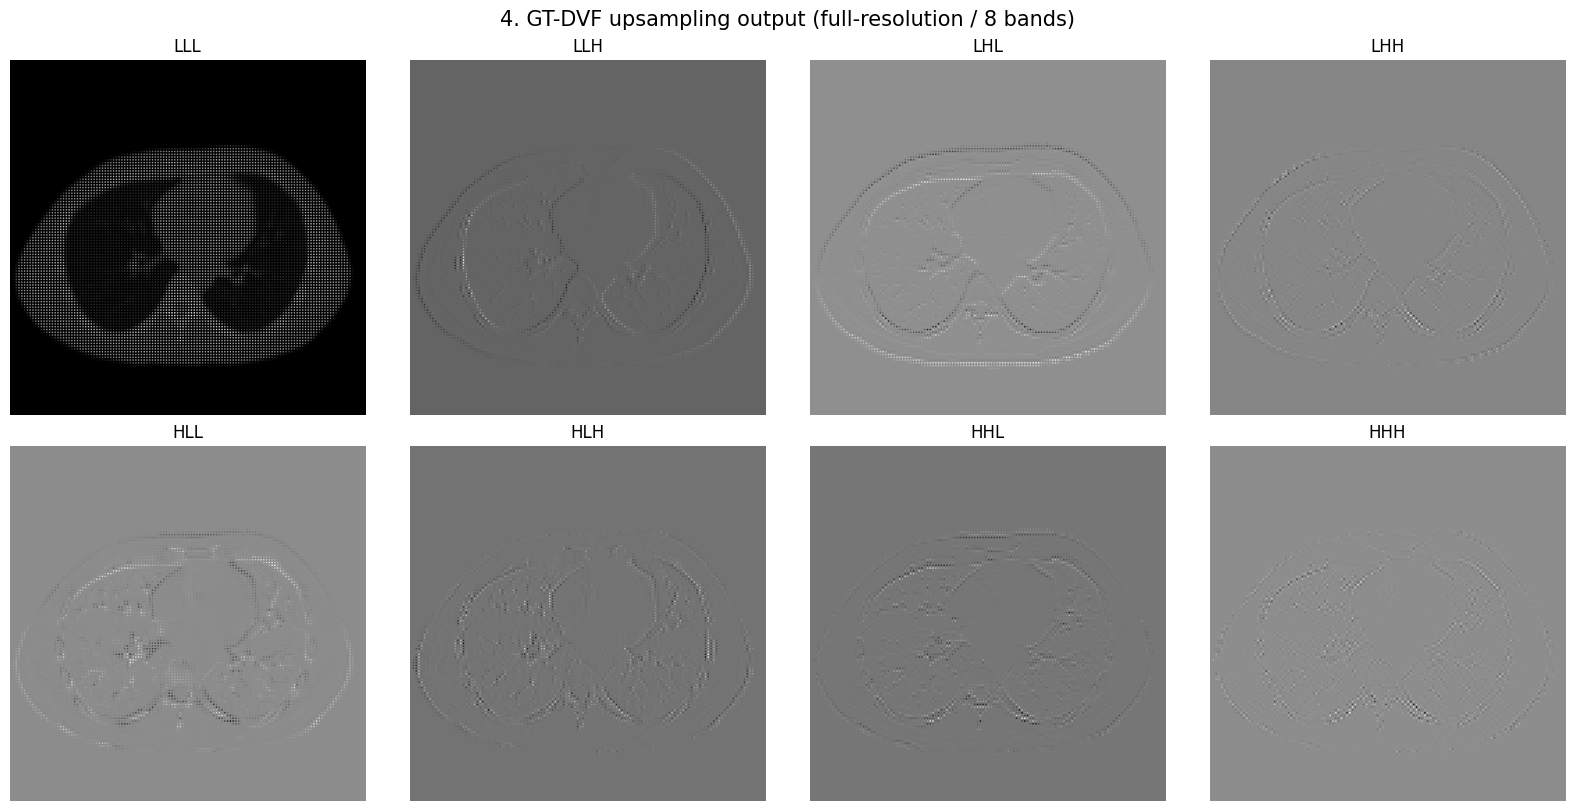

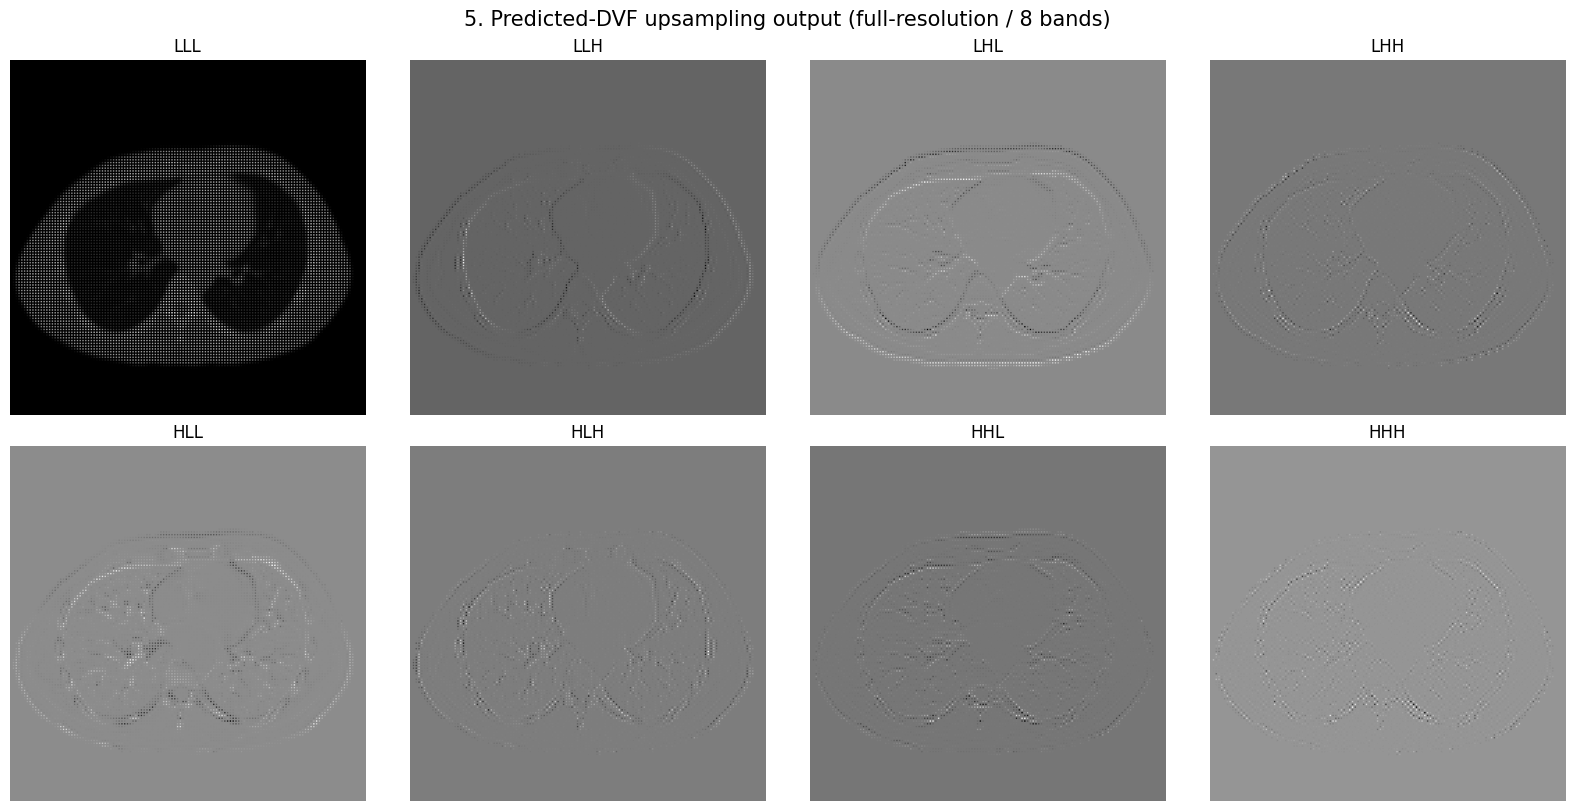

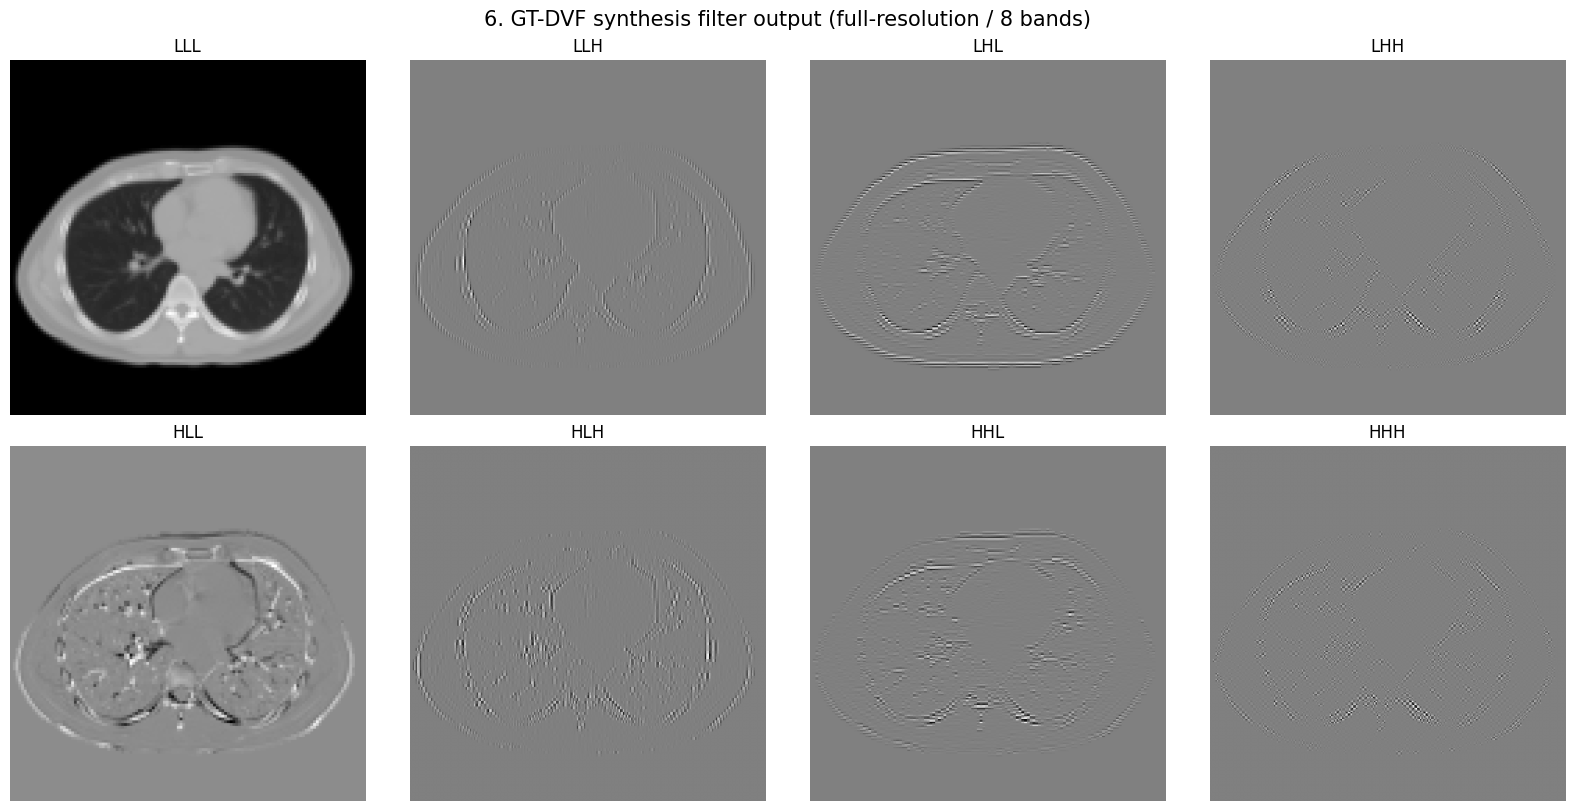

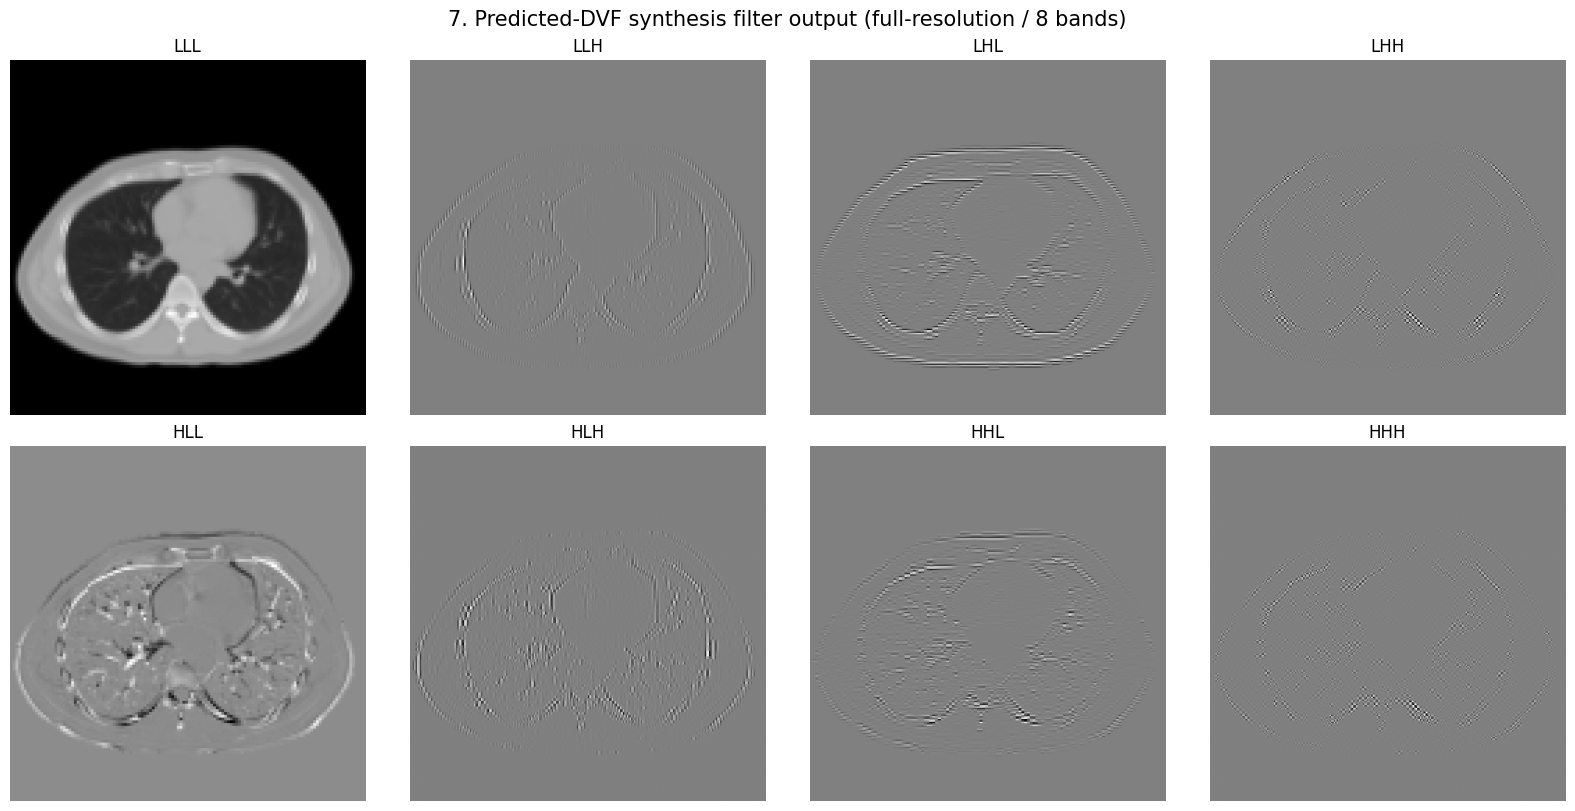

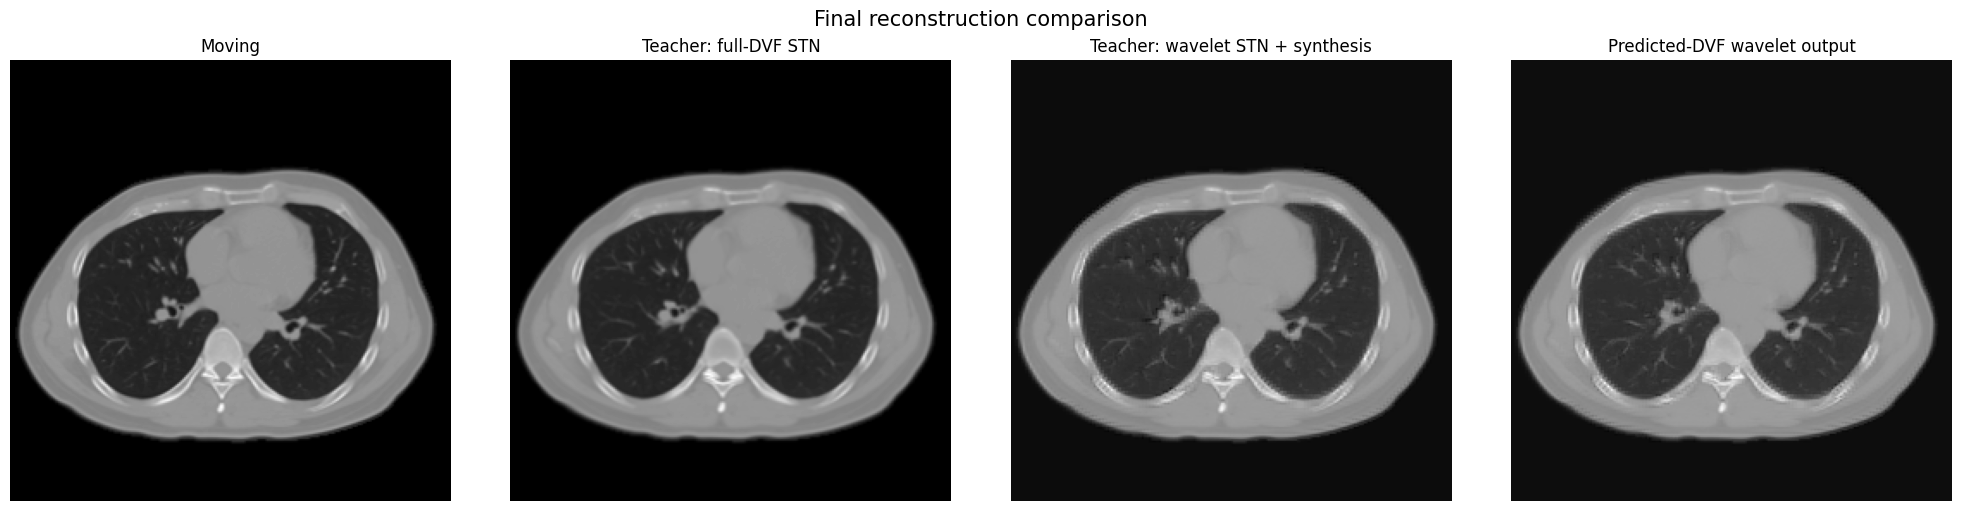


Saved diagnostic images:
D:\Saito\dvf_wavelet_diagnostic_pair1


In [10]:
# ============================================================
# Run one diagnostic case
# ============================================================

moving_path = find_moving_file(TEST_PAIR_DIR)

print("Moving file:", moving_path.name)

moving_np = load_npz_volume(moving_path)

moving = torch.from_numpy(
    moving_np
).unsqueeze(0).unsqueeze(0).to(
    device=device,
    dtype=torch.float32,
)

with torch.no_grad():
    # --------------------------------------------------------
    # 1. Artificial ground-truth full DVF
    # --------------------------------------------------------
    true_flow_full, true_flow_low = (
        make_artificial_true_dvf(
            batch_size=1,
            shift=ARTIFICIAL_SHIFT_VOX,
        )
    )

    # Curriculum時の教師画像:
    # full-resolution STNによるMovingの変形結果
    teacher_full = transformer_full(
        moving,
        true_flow_full,
    )

    # --------------------------------------------------------
    # 2. Haar analysis: 8 bands / low resolution
    # --------------------------------------------------------
    moving_w = analysis(moving)

   # ========================================================
    # 条件A: 2回目Gaussianなし
    # すでに正解DVFは最初の粗い格子で1回だけGaussian済み
    # ========================================================

    true_flow_low_no_second_gauss = true_flow_low

    true_warped_low_no_second = warp_wavelet_highfreq_nearest(
        moving_w,
        true_flow_low_no_second_gauss,
    )

    true_warped_up_no_second = up_sampling_3d(
        true_warped_low_no_second
    )

    recon_no_second_gauss, filtered_no_second_gauss = (
        synthesis_filter_3d(
            true_warped_up_no_second
        )
    )


    # ========================================================
    # 条件B: low-DVFへ2回目Gaussianあり
    # ========================================================

    true_flow_low_second_gauss = gaussian_smooth_3d(
        true_flow_low_no_second_gauss,
        sigma=2.0,
    )

    true_warped_low_second = warp_wavelet_highfreq_nearest(
        moving_w,
        true_flow_low_second_gauss,
    )

    true_warped_up_second = up_sampling_3d(
        true_warped_low_second
    )

    recon_second_gauss, filtered_second_gauss = (
        synthesis_filter_3d(
            true_warped_up_second
        )
    )


    # 既存の下側コードとの互換用
    # teacher_wavelet は「2回目Gaussianなし」の再構成画像にする
    teacher_wavelet = recon_no_second_gauss
    true_warped_low = true_warped_low_no_second
    true_warped_up = true_warped_up_no_second
    true_filtered_bands = filtered_no_second_gauss

    # --------------------------------------------------------
    # 6. 80k CurriculumモデルによるDVF予測
    #    学習時と同じ入力:
    #    Moving と full-STN教師画像
    # --------------------------------------------------------
    teacher_input_w = analysis(teacher_full)

    pred_flow_low = model(
        moving_w,
        teacher_input_w,
    )

    pred_flow_full = low_dvf_to_full_dvf(
        pred_flow_low
    )

    # --------------------------------------------------------
    # 7. 予測DVFを8周波数STNへ適用
    # --------------------------------------------------------
    pred_warped_low = warp_wavelet_highfreq_nearest(
        moving_w,
        pred_flow_low,
    )

    # --------------------------------------------------------
    # 8. upsampling: 8 bands / full resolution
    # --------------------------------------------------------
    pred_warped_up = up_sampling_3d(
        pred_warped_low
    )

    # --------------------------------------------------------
    # 9. synthesis filter: 8 bands / full resolution
    # --------------------------------------------------------
    predicted_wavelet, pred_filtered_bands = (
        synthesis_filter_3d(
            pred_warped_up
        )
    )

    # --------------------------------------------------------
    # Numeric checks
    # --------------------------------------------------------
    print("\n========== DVF statistics ==========")

    flow_statistics(
        "GT low DVF",
        true_flow_low,
    )
    flow_statistics(
        "Predicted low DVF",
        pred_flow_low,
    )
    flow_statistics(
        "GT full DVF",
        true_flow_full,
    )
    flow_statistics(
        "Predicted full DVF",
        pred_flow_full,
    )

    print("\n========== Error checks ==========")

    print(
        "DVF MSE (pred low vs GT low):",
        F.mse_loss(
            pred_flow_low.float(),
            true_flow_low.float(),
        ).item(),
    )

    print(
        "Teacher full-STN vs "
        "teacher wavelet reconstruction MSE:",
        F.mse_loss(
            teacher_full.float(),
            teacher_wavelet.float(),
        ).item(),
    )

    print(
        "Teacher full-STN vs "
        "predicted-DVF wavelet output MSE:",
        F.mse_loss(
            teacher_full.float(),
            predicted_wavelet.float(),
        ).item(),
    )

    print(
        "GT full-DVF vs low->full-DVF MSE:",
        F.mse_loss(
            true_flow_full.float(),
            low_dvf_to_full_dvf(
                true_flow_low
            ).float(),
        ).item(),
    )

    # --------------------------------------------------------
    # Save and display every requested stage
    # --------------------------------------------------------
    show_8_bands(
        moving_w,
        VIEW_Z_LOW,
        "1. Haar analysis: Moving "
        "(low-resolution / 8 bands)",
        OUTPUT_DIR / "01_moving_wavelet_low_8bands.png",
    )

    show_8_bands(
        true_warped_low,
        VIEW_Z_LOW,
        "2. GT low-DVF STN output "
        "(low-resolution / 8 bands)",
        OUTPUT_DIR / "02_gt_dvf_stn_low_8bands.png",
    )

    show_8_bands(
        pred_warped_low,
        VIEW_Z_LOW,
        "3. Predicted low-DVF STN output "
        "(low-resolution / 8 bands)",
        OUTPUT_DIR / "03_pred_dvf_stn_low_8bands.png",
    )

    show_8_bands(
        true_warped_up,
        VIEW_Z_FULL,
        "4. GT-DVF upsampling output "
        "(full-resolution / 8 bands)",
        OUTPUT_DIR / "04_gt_upsampled_full_8bands.png",
    )

    show_8_bands(
        pred_warped_up,
        VIEW_Z_FULL,
        "5. Predicted-DVF upsampling output "
        "(full-resolution / 8 bands)",
        OUTPUT_DIR / "05_pred_upsampled_full_8bands.png",
    )

    show_8_bands(
        true_filtered_bands,
        VIEW_Z_FULL,
        "6. GT-DVF synthesis filter output "
        "(full-resolution / 8 bands)",
        OUTPUT_DIR / "06_gt_synthesis_filtered_8bands.png",
    )

    show_8_bands(
        pred_filtered_bands,
        VIEW_Z_FULL,
        "7. Predicted-DVF synthesis filter output "
        "(full-resolution / 8 bands)",
        OUTPUT_DIR / "07_pred_synthesis_filtered_8bands.png",
    )

    show_final_images(
        moving,
        teacher_full,
        teacher_wavelet,
        predicted_wavelet,
        OUTPUT_DIR / "08_final_reconstruction_comparison.png",
    )

print("\nSaved diagnostic images:")
print(OUTPUT_DIR.resolve())

In [11]:
compare_images(
    "No second Gaussian: full-STN vs wavelet reconstruction",
    teacher_full,
    recon_no_second_gauss,
)

compare_images(
    "Second Gaussian: full-STN vs wavelet reconstruction",
    teacher_full,
    recon_second_gauss,
)

NameError: name 'compare_images' is not defined

In [ ]:
def compare_images(name, reference, image):
    difference = image.float() - reference.float()

    mae = difference.abs().mean().item()
    mse = (difference ** 2).mean().item()
    rmse = torch.sqrt((difference ** 2).mean()).item()

    reference_flat = reference.float().flatten()
    image_flat = image.float().flatten()

    ncc = torch.corrcoef(
        torch.stack([reference_flat, image_flat])
    )[0, 1].item()

    print(f"\n=== {name} ===")
    print(f"MAE : {mae:.8f}")
    print(f"MSE : {mse:.8f}")
    print(f"RMSE: {rmse:.8f}")
    print(f"NCC : {ncc:.8f}")


# Full-resolution正解DVFで直接warpした教師画像
# と、正解DVFを半分にしてwavelet STN→加算した画像の比較
compare_images(
    "GT full-STN vs GT wavelet-STN + summed image",
    teacher_full,
    teacher_wavelet,
)

# 正解DVF経路の加算後画像と、80kモデルのDVF経路の加算後画像の比較
compare_images(
    "GT summed image vs predicted-DVF summed image",
    teacher_wavelet,
    predicted_wavelet,
)

# Full-STN教師画像と、予測DVF経路の最終加算後画像の比較
compare_images(
    "GT full-STN vs predicted-DVF summed image",
    teacher_full,
    predicted_wavelet,
)


=== GT full-STN vs GT wavelet-STN + summed image ===
MAE : 0.00788001
MSE : 0.00056963
RMSE: 0.02386692
NCC : 0.99567401

=== GT summed image vs predicted-DVF summed image ===
MAE : 0.00254806
MSE : 0.00014628
RMSE: 0.01209447
NCC : 0.99892092

=== GT full-STN vs predicted-DVF summed image ===
MAE : 0.00784513
MSE : 0.00056122
RMSE: 0.02369017
NCC : 0.99580008


In [ ]:
def show_summed_comparison(
    teacher_full,
    teacher_wavelet,
    predicted_wavelet,
    output_path,
):
    z = min(VIEW_Z_FULL, teacher_full.shape[2] - 1)

    full_np = teacher_full[0, 0, z].cpu().numpy()
    gt_sum_np = teacher_wavelet[0, 0, z].cpu().numpy()
    pred_sum_np = predicted_wavelet[0, 0, z].cpu().numpy()

    gt_difference = np.abs(gt_sum_np - full_np)
    pred_difference = np.abs(pred_sum_np - full_np)

    fig, axes = plt.subplots(
        2,
        3,
        figsize=(15, 10),
        constrained_layout=True,
    )

    image_items = [
        (full_np, "Teacher: full-DVF STN", "gray", 0, 1),
        (gt_sum_np, "GT-DVF wavelet: summed", "gray", 0, 1),
        (pred_sum_np, "Predicted-DVF wavelet: summed", "gray", 0, 1),
        (gt_difference, "|GT summed − Full-STN|", "hot", 0, None),
        (pred_difference, "|Pred summed − Full-STN|", "hot", 0, None),
    ]

    for axis, (image, title, cmap, vmin, vmax) in zip(
        axes.ravel(),
        image_items,
    ):
        axis.imshow(
            image,
            cmap=cmap,
            vmin=vmin,
            vmax=vmax,
        )
        axis.set_title(title)
        axis.axis("off")

    axes.ravel()[-1].axis("off")

    fig.suptitle(
        "Summed-image comparison after synthesis",
        fontsize=15,
    )

    fig.savefig(
        output_path,
        dpi=180,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(fig)

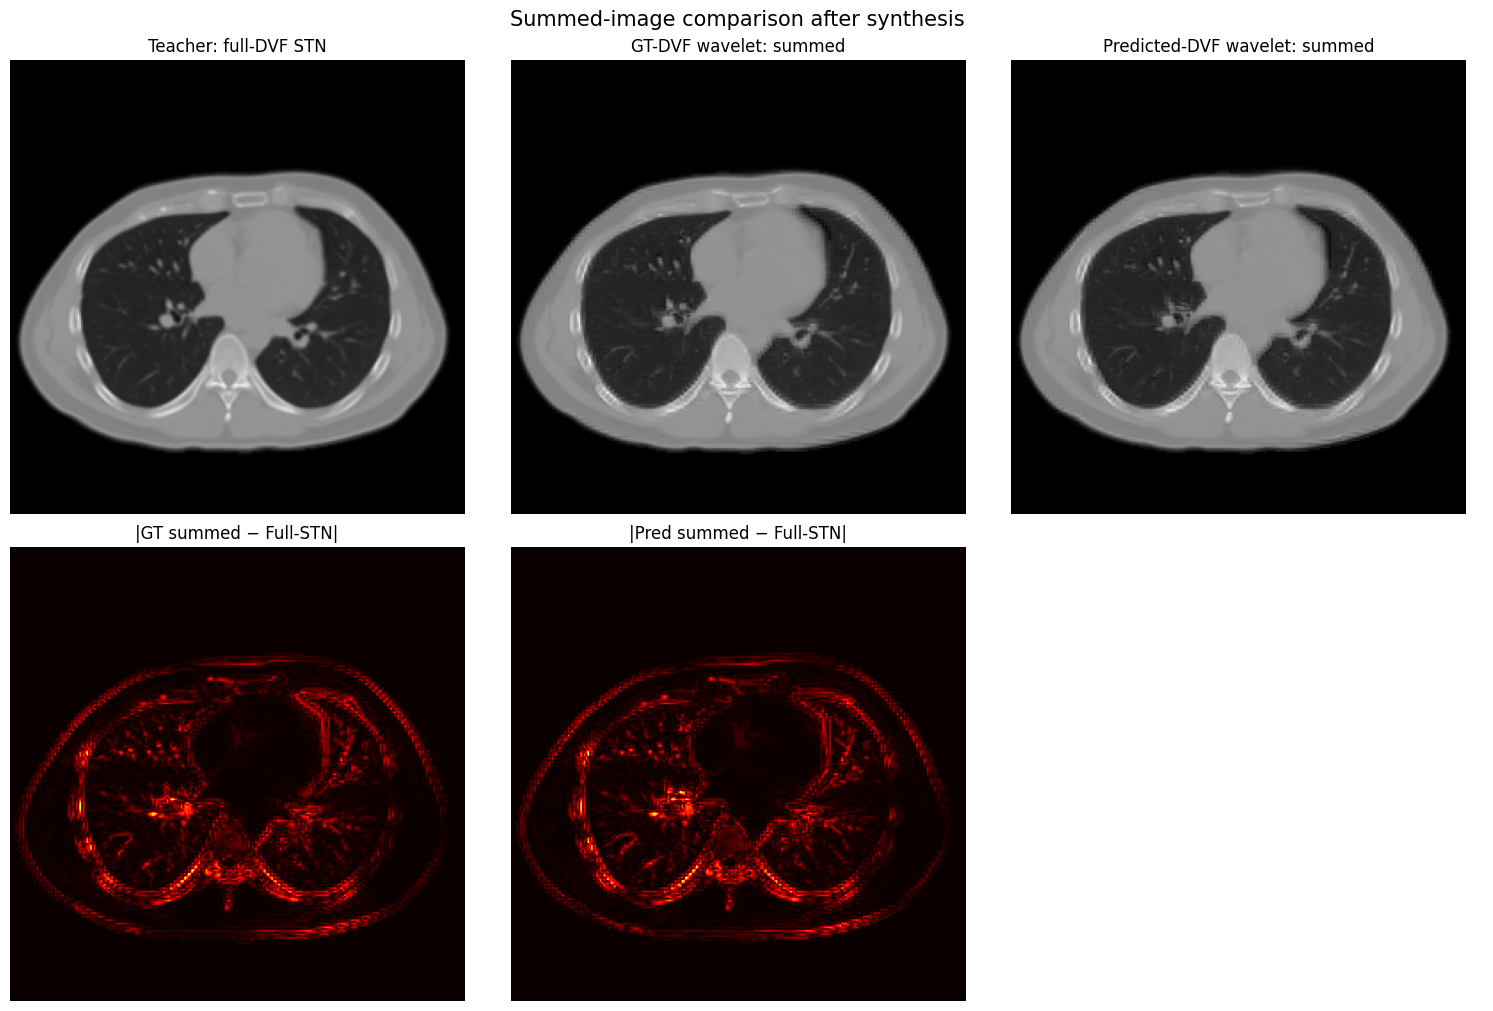

In [ ]:
show_summed_comparison(
    teacher_full,
    teacher_wavelet,
    predicted_wavelet,
    OUTPUT_DIR / "09_summed_image_comparison.png",
)

Moving: registered_masked_A_MIC00197_2018_0428.npz
Fixed : fixed_masked_B_MIC00197_2019_0406.npz

=== モデルなし・ゼロDVFの評価 ===


,condition,MAE,MSE,RMSE,NCC
0,A_before_registration_moving_vs_fixed,2.916339e-02,9.782054e-03,9.890426e-02,0.928402
1,B_zero_full_STN_vs_fixed,2.916340e-02,9.782052e-03,9.890426e-02,0.928402
2,C_zero_wavelet_synthesis_vs_fixed,2.916339e-02,9.782052e-03,9.890426e-02,0.928402
3,D_wavelet_round_trip_vs_original_moving,7.169874e-08,4.578738e-14,2.139799e-07,1.000000


Saved: D:\Saito\dvf_wavelet_diagnostic_pair1\no_model_zero_dvf_baseline\no_model_zero_dvf_metrics.csv


C:\Users\user\AppData\Local\Temp\ipykernel_23580\2022492037.py:347: UserWarning: Glyph 12514 (\N{KATAKANA LETTER MO}) missing from font(s) DejaVu Sans.
  fig.savefig(
C:\Users\user\AppData\Local\Temp\ipykernel_23580\2022492037.py:347: UserWarning: Glyph 12487 (\N{KATAKANA LETTER DE}) missing from font(s) DejaVu Sans.
  fig.savefig(
C:\Users\user\AppData\Local\Temp\ipykernel_23580\2022492037.py:347: UserWarning: Glyph 12523 (\N{KATAKANA LETTER RU}) missing from font(s) DejaVu Sans.
  fig.savefig(
C:\Users\user\AppData\Local\Temp\ipykernel_23580\2022492037.py:347: UserWarning: Glyph 12394 (\N{HIRAGANA LETTER NA}) missing from font(s) DejaVu Sans.
  fig.savefig(
C:\Users\user\AppData\Local\Temp\ipykernel_23580\2022492037.py:347: UserWarning: Glyph 12375 (\N{HIRAGANA LETTER SI}) missing from font(s) DejaVu Sans.
  fig.savefig(
C:\Users\user\AppData\Local\Temp\ipykernel_23580\2022492037.py:347: UserWarning: Glyph 12539 (\N{KATAKANA MIDDLE DOT}) missing from font(s) DejaVu Sans.
  fig.savefi

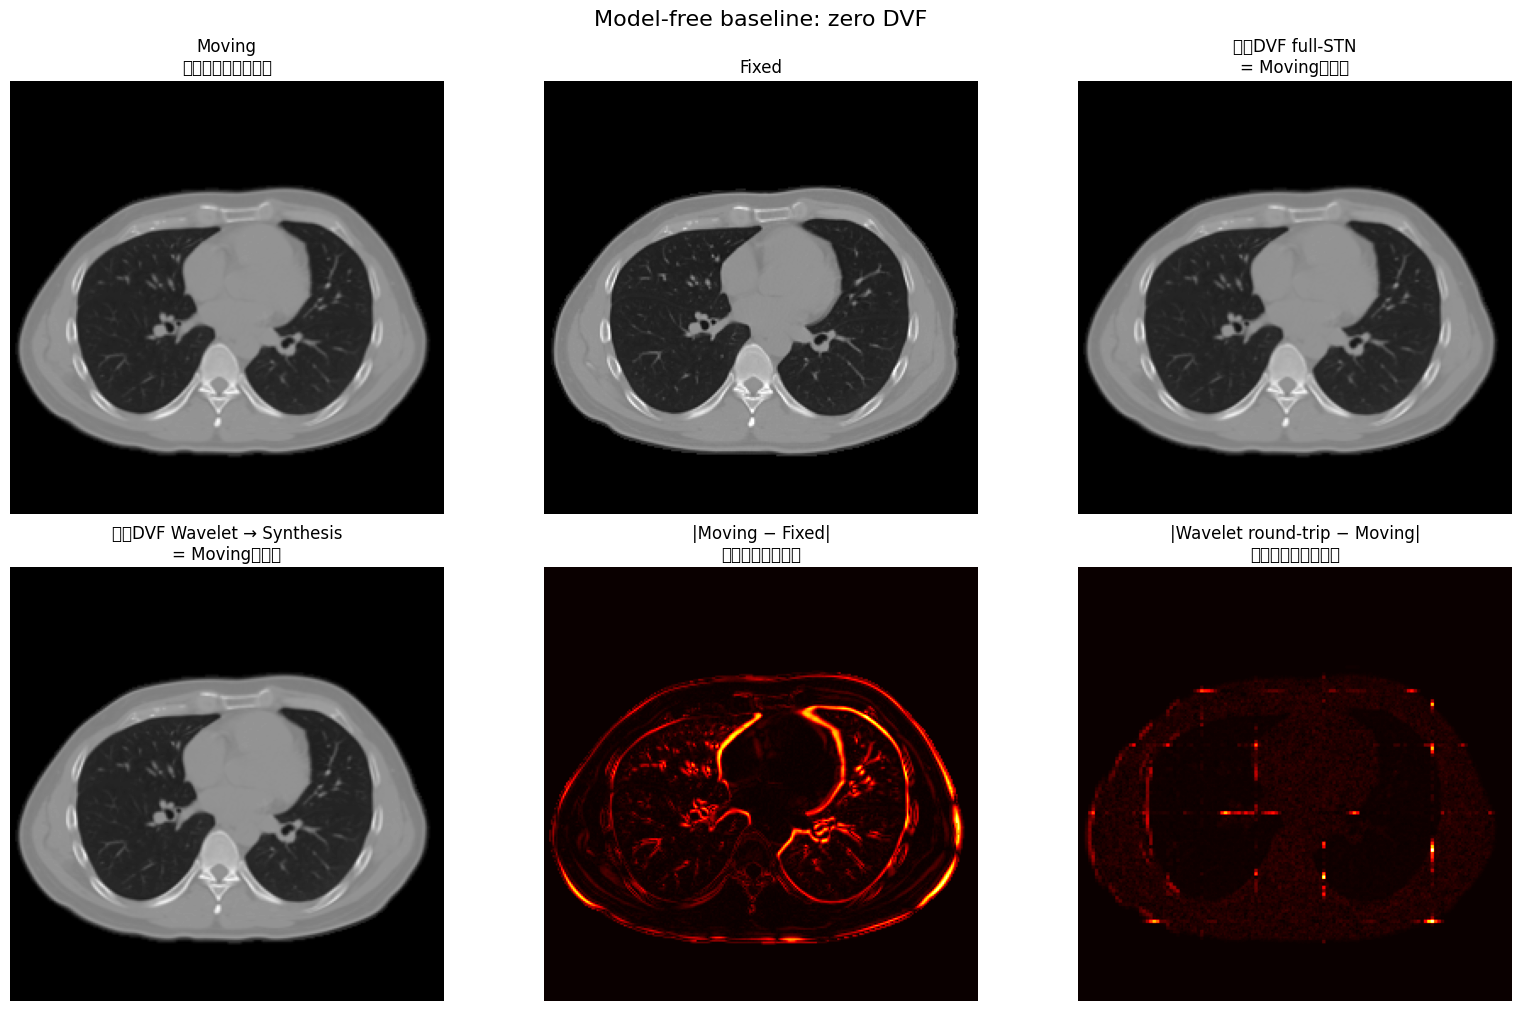

Saved: D:\Saito\dvf_wavelet_diagnostic_pair1\no_model_zero_dvf_baseline\no_model_zero_dvf_baseline.png


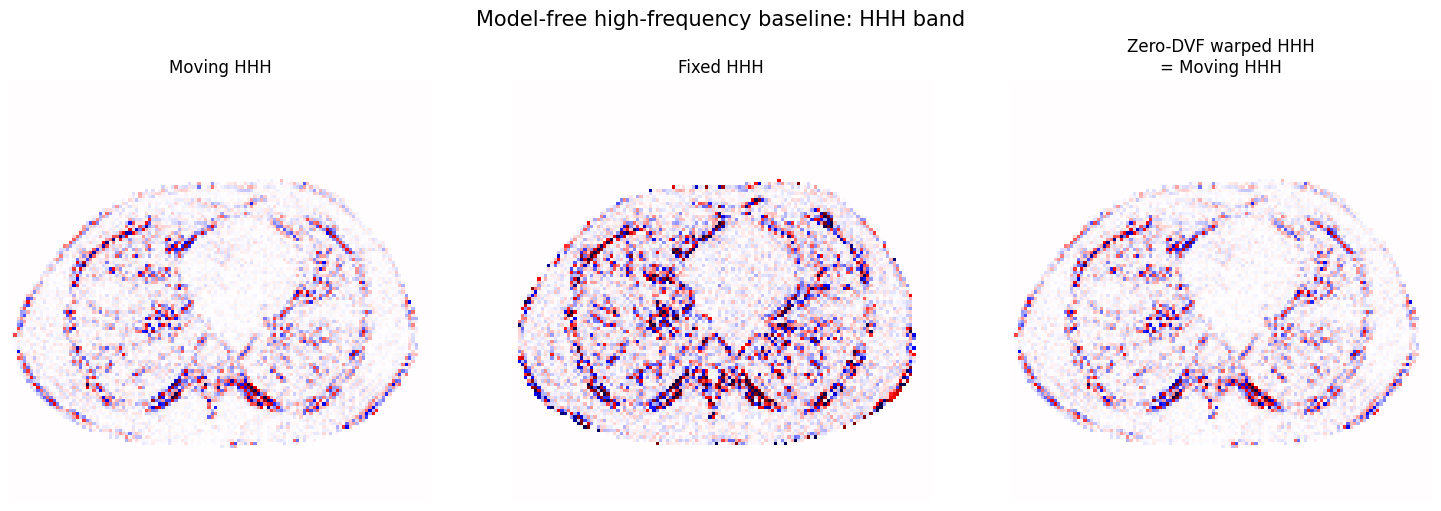

Saved: D:\Saito\dvf_wavelet_diagnostic_pair1\no_model_zero_dvf_baseline\no_model_zero_dvf_HHH.png


In [12]:
# ============================================================
# TestData: モデルなし・DVF=0 の基準評価
#
# 前の診断セルで定義済みの以下を使う:
# load_npz_volume, find_moving_file, natural_key,
# analysis, up_sampling_3d, synthesis_filter_3d,
# transformer_full, warp_wavelet_highfreq_nearest,
# FULL_SIZE, LOW_SIZE, device, TEST_PAIR_DIR
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F


# ------------------------------------------------------------
# 保存先
# ------------------------------------------------------------
NO_MODEL_DIR = Path(
    "dvf_wavelet_diagnostic_pair1"
    r"\no_model_zero_dvf_baseline"
)
NO_MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


# ------------------------------------------------------------
# Moving以外のNPZをFixedとして取得
# ------------------------------------------------------------
pair_files = sorted(
    TEST_PAIR_DIR.glob("*.npz"),
    key=natural_key,
)

if len(pair_files) != 2:
    raise RuntimeError(
        f"{TEST_PAIR_DIR} にnpzが2つ必要です: {pair_files}"
    )

moving_path = find_moving_file(TEST_PAIR_DIR)

fixed_path = next(
    path
    for path in pair_files
    if path != moving_path
)

print("Moving:", moving_path.name)
print("Fixed :", fixed_path.name)


# ------------------------------------------------------------
# 画像読込
# ------------------------------------------------------------
moving_np = load_npz_volume(moving_path)
fixed_np = load_npz_volume(fixed_path)

moving_no_model = torch.from_numpy(
    moving_np
).unsqueeze(0).unsqueeze(0).to(
    device=device,
    dtype=torch.float32,
)

fixed_no_model = torch.from_numpy(
    fixed_np
).unsqueeze(0).unsqueeze(0).to(
    device=device,
    dtype=torch.float32,
)


# ------------------------------------------------------------
# 指標関数
# ------------------------------------------------------------
def calculate_image_metrics(reference, image):
    reference = reference.float()
    image = image.float()

    difference = image - reference

    mae = difference.abs().mean().item()
    mse = difference.square().mean().item()
    rmse = float(np.sqrt(mse))

    reference_flat = reference.flatten()
    image_flat = image.flatten()

    ncc = torch.corrcoef(
        torch.stack(
            [reference_flat, image_flat]
        )
    )[0, 1].item()

    return {
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "NCC": ncc,
    }


# ============================================================
# モデルなし・ゼロDVF経路
# ============================================================
with torch.no_grad():

    # --------------------------------------------------------
    # A. full-resolution STNへゼロDVFを入れる
    #    出力は原理上Movingと同じ
    # --------------------------------------------------------
    zero_flow_full = torch.zeros(
        1,
        3,
        *FULL_SIZE,
        device=device,
        dtype=torch.float32,
    )

    moved_zero_full_stn = transformer_full(
        moving_no_model,
        zero_flow_full,
    )

    # --------------------------------------------------------
    # B. Wavelet経路へゼロDVFを入れる
    #    8帯域を動かさず、synthesisだけして戻す
    # --------------------------------------------------------
    zero_flow_low = torch.zeros(
        1,
        3,
        *LOW_SIZE,
        device=device,
        dtype=torch.float32,
    )

    moving_wavelet = analysis(moving_no_model)
    fixed_wavelet = analysis(fixed_no_model)

    zero_warped_wavelet = (
        warp_wavelet_highfreq_nearest(
            moving_wavelet,
            zero_flow_low,
        )
    )

    zero_warped_up = up_sampling_3d(
        zero_warped_wavelet
    )

    moved_zero_wavelet, zero_filtered_bands = (
        synthesis_filter_3d(
            zero_warped_up
        )
    )


# ============================================================
# 数値評価
# ============================================================
rows = []

for name, image in [
    (
        "A_before_registration_moving_vs_fixed",
        moving_no_model,
    ),
    (
        "B_zero_full_STN_vs_fixed",
        moved_zero_full_stn,
    ),
    (
        "C_zero_wavelet_synthesis_vs_fixed",
        moved_zero_wavelet,
    ),
]:
    metrics = calculate_image_metrics(
        fixed_no_model,
        image,
    )

    metrics["condition"] = name
    rows.append(metrics)

round_trip_metrics = calculate_image_metrics(
    moving_no_model,
    moved_zero_wavelet,
)

round_trip_metrics["condition"] = (
    "D_wavelet_round_trip_vs_original_moving"
)
rows.append(round_trip_metrics)

no_model_metrics_df = pd.DataFrame(rows)[
    ["condition", "MAE", "MSE", "RMSE", "NCC"]
]

print("\n=== モデルなし・ゼロDVFの評価 ===")
display(no_model_metrics_df)

metrics_path = (
    NO_MODEL_DIR / "no_model_zero_dvf_metrics.csv"
)

no_model_metrics_df.to_csv(
    metrics_path,
    index=False,
    encoding="utf-8-sig",
)

print("Saved:", metrics_path.resolve())


# ============================================================
# 画像表示
# ============================================================
z_full = min(
    VIEW_Z_FULL,
    moving_no_model.shape[2] - 1,
)

moving_slice = (
    moving_no_model[0, 0, z_full]
    .detach()
    .cpu()
    .numpy()
)

fixed_slice = (
    fixed_no_model[0, 0, z_full]
    .detach()
    .cpu()
    .numpy()
)

zero_full_slice = (
    moved_zero_full_stn[0, 0, z_full]
    .detach()
    .cpu()
    .numpy()
)

zero_wavelet_slice = (
    moved_zero_wavelet[0, 0, z_full]
    .detach()
    .cpu()
    .numpy()
)

diff_before = np.abs(
    moving_slice - fixed_slice
)

diff_zero_wavelet = np.abs(
    zero_wavelet_slice - fixed_slice
)

round_trip_diff = np.abs(
    zero_wavelet_slice - moving_slice
)

fig, axes = plt.subplots(
    2,
    3,
    figsize=(16, 10),
    constrained_layout=True,
)

image_items = [
    (
        moving_slice,
        "Moving\nモデルなし・未登録",
        "gray",
        0,
        1,
    ),
    (
        fixed_slice,
        "Fixed",
        "gray",
        0,
        1,
    ),
    (
        zero_full_slice,
        "ゼロDVF full-STN\n= Movingのまま",
        "gray",
        0,
        1,
    ),
    (
        zero_wavelet_slice,
        "ゼロDVF Wavelet → Synthesis\n= Movingのまま",
        "gray",
        0,
        1,
    ),
    (
        diff_before,
        "|Moving − Fixed|\n位置合わせ前の差",
        "hot",
        0,
        None,
    ),
    (
        round_trip_diff,
        "|Wavelet round-trip − Moving|\n変形なし再構成誤差",
        "hot",
        0,
        None,
    ),
]

for axis, (
    image,
    title,
    cmap,
    vmin,
    vmax,
) in zip(
    axes.ravel(),
    image_items,
):
    axis.imshow(
        image,
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
    )
    axis.set_title(title)
    axis.axis("off")

fig.suptitle(
    "Model-free baseline: zero DVF",
    fontsize=16,
)

figure_path = (
    NO_MODEL_DIR / "no_model_zero_dvf_baseline.png"
)

fig.savefig(
    figure_path,
    dpi=180,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

print("Saved:", figure_path.resolve())


# ============================================================
# 高周波帯域も表示
# ============================================================
z_low = min(
    VIEW_Z_LOW,
    moving_wavelet.shape[2] - 1,
)

band_index = BAND_NAMES.index("HHH")

hh_images = [
    (
        moving_wavelet[0, band_index, z_low]
        .detach().cpu().numpy(),
        "Moving HHH",
    ),
    (
        fixed_wavelet[0, band_index, z_low]
        .detach().cpu().numpy(),
        "Fixed HHH",
    ),
    (
        zero_warped_wavelet[0, band_index, z_low]
        .detach().cpu().numpy(),
        "Zero-DVF warped HHH\n= Moving HHH",
    ),
]

vmax_hhh = max(
    float(
        np.percentile(
            np.abs(image),
            99,
        )
    )
    for image, _ in hh_images
)

fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 5),
    constrained_layout=True,
)

for axis, (image, title) in zip(
    axes,
    hh_images,
):
    axis.imshow(
        image,
        cmap="seismic",
        vmin=-vmax_hhh,
        vmax=vmax_hhh,
    )
    axis.set_title(title)
    axis.axis("off")

fig.suptitle(
    "Model-free high-frequency baseline: HHH band",
    fontsize=15,
)

hhh_path = (
    NO_MODEL_DIR / "no_model_zero_dvf_HHH.png"
)

fig.savefig(
    hhh_path,
    dpi=180,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

print("Saved:", hhh_path.resolve())

In [ ]:
with torch.no_grad():
    moving_w = analysis(moving)

    # STNなしで、そのまま再構成
    moving_up = up_sampling_3d(moving_w)

    reconstructed_no_stn, _ = synthesis_filter_3d(
        moving_up
    )

    print(
        "Analysis → inverse wavelet only MAE:",
        F.l1_loss(
            moving,
            reconstructed_no_stn,
        ).item(),
    )

    print(
        "Analysis → inverse wavelet only RMSE:",
        torch.sqrt(
            F.mse_loss(
                moving,
                reconstructed_no_stn,
            )
        ).item(),
    )

Analysis → inverse wavelet only MAE: 4.034399125885102e-08
Analysis → inverse wavelet only RMSE: 7.175393079705827e-08


In [ ]:
with torch.no_grad():
    zero_flow = torch.zeros(
        1,
        3,
        64,
        128,
        128,
        device=device,
    )

    zero_stn_w = transformer_low_linear(
        moving_w,
        zero_flow,
    )

    zero_stn_up = up_sampling_3d(
        zero_stn_w
    )

    reconstructed_zero_stn, _ = synthesis_filter_3d(
        zero_stn_up
    )

    print(
        "Zero-DVF STN → inverse wavelet MAE:",
        F.l1_loss(
            moving,
            reconstructed_zero_stn,
        ).item(),
    )

Zero-DVF STN → inverse wavelet MAE: 7.490934450515851e-08



=== Integer shift: Full 6 vox / Low 3.0 vox ===
MAE=0.00000019, RMSE=0.00000054, NCC=1.00000000

=== Non-integer shift: Full 5 vox / Low 2.5 vox ===
MAE=0.00655629, RMSE=0.01889553, NCC=0.99747050


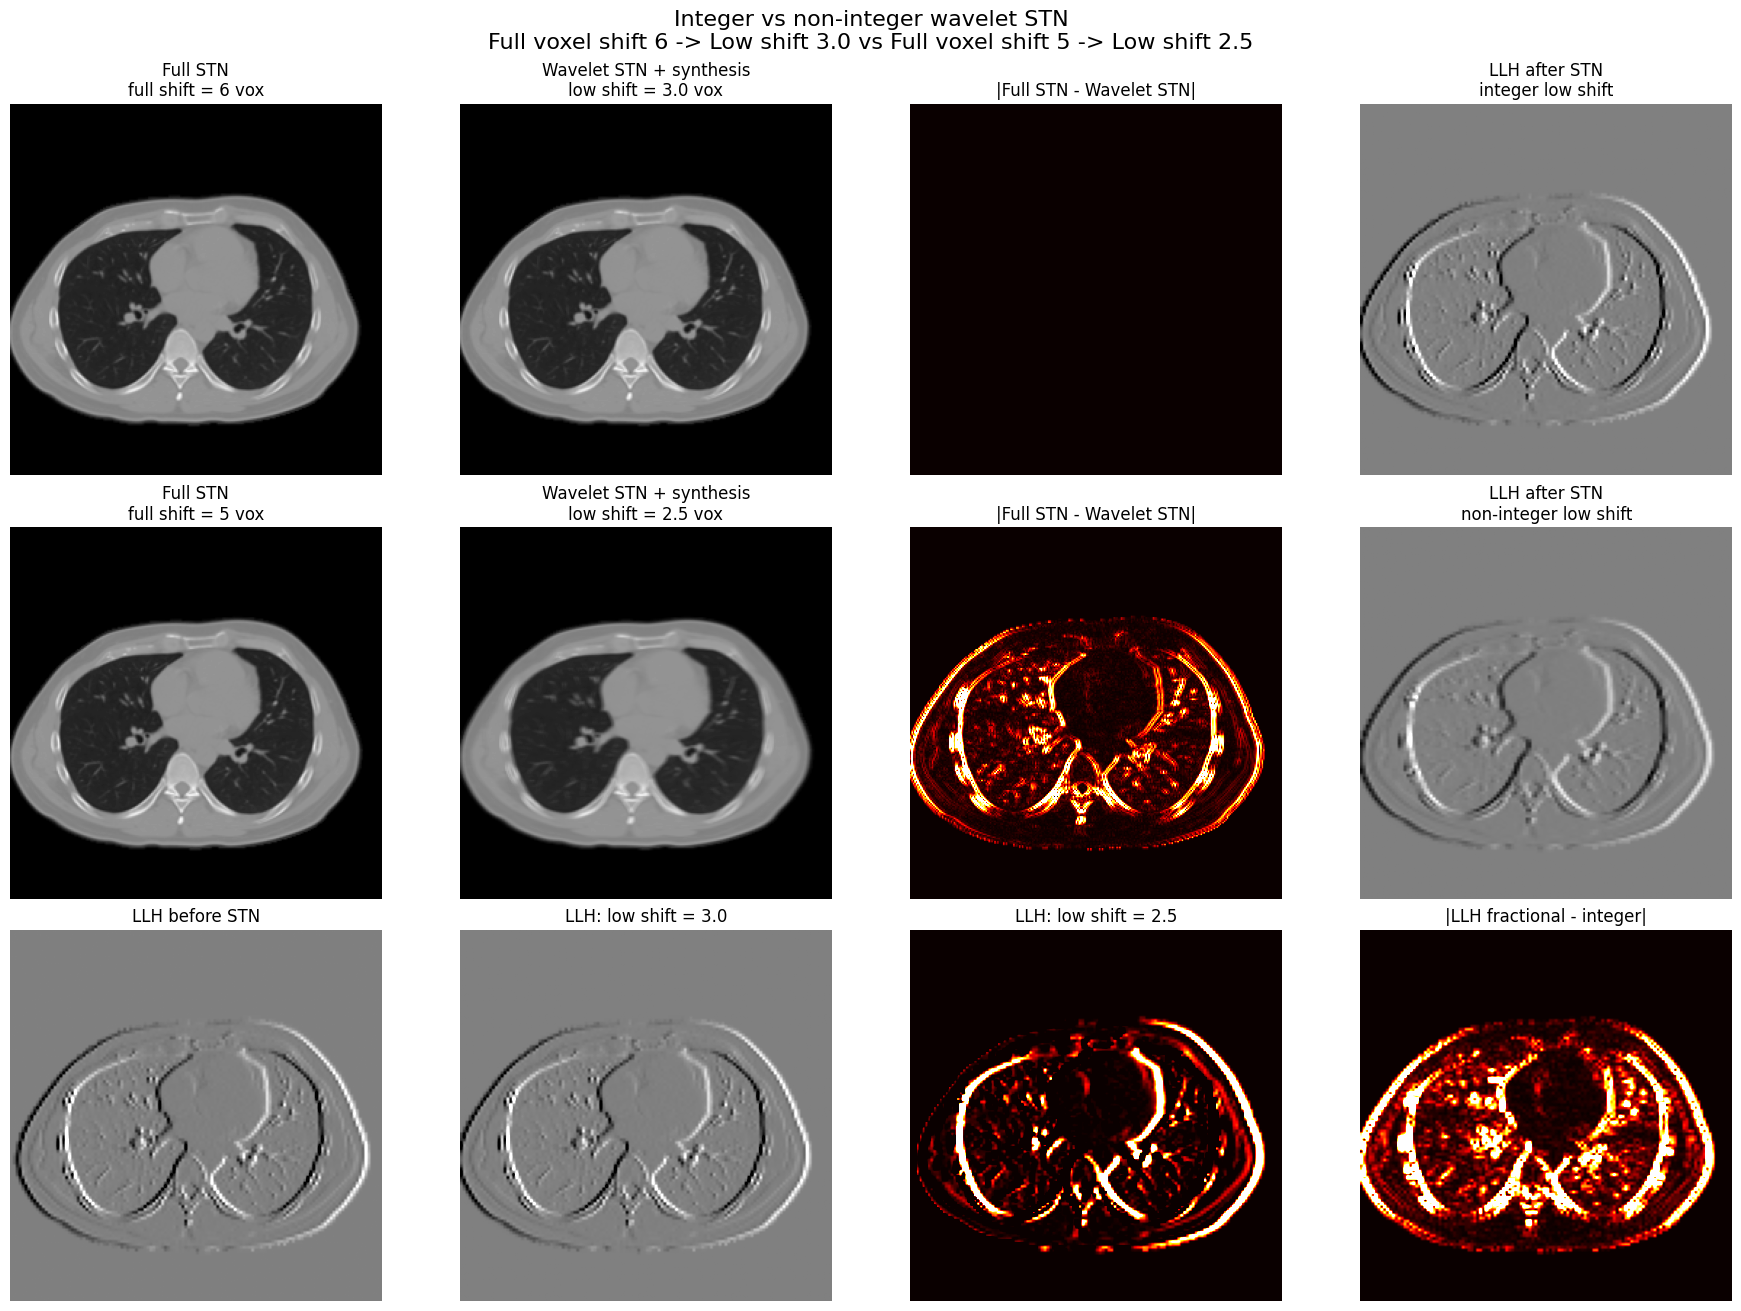


Saved: dvf_wavelet_diagnostic_pair1\10_integer_vs_noninteger_wavelet_stn.png


In [ ]:
# ============================================================
# Wavelet STNの「整数移動」と「非整数移動」を比較
#
# Full画像で 6 voxel移動 -> Low画像では 3.0 voxel移動
# Full画像で 5 voxel移動 -> Low画像では 2.5 voxel移動
#
# 後者だけlow-wavelet STNで補間が必要になる
# ============================================================

def reconstruct_from_wavelet_stn(
    moving_w,
    flow_low,
):
    """
    全8周波数をtrilinear STNで変形してから再構成する。
    high-frequency nearestは使わず、
    STNの補間そのものだけを観察する。
    """
    warped_w = transformer_low_linear(
        moving_w,
        flow_low,
    )

    warped_up = up_sampling_3d(
        warped_w
    )

    reconstructed, filtered_bands = synthesis_filter_3d(
        warped_up
    )

    return reconstructed, warped_w, filtered_bands


def make_constant_x_flow(
    full_shift_vox,
):
    """
    x方向だけ一定量だけ動かすDVFを作成。

    full_shift_vox=6なら、
    low-resolution DVFは3 voxel移動になる。
    """
    flow_full = torch.zeros(
        1,
        3,
        *FULL_SIZE,
        device=device,
    )

    flow_low = torch.zeros(
        1,
        3,
        *LOW_SIZE,
        device=device,
    )

    # channel 2 = x / W方向
    flow_full[:, 2] = full_shift_vox
    flow_low[:, 2] = full_shift_vox / 2.0

    return flow_full, flow_low


def central_error_metrics(
    reference,
    image,
    margin=16,
):
    """
    端部のzero padding影響を除外して誤差を計算。
    """
    reference_roi = reference[
        :,
        :,
        margin:-margin,
        margin:-margin,
        margin:-margin,
    ]

    image_roi = image[
        :,
        :,
        margin:-margin,
        margin:-margin,
        margin:-margin,
    ]

    difference = image_roi - reference_roi

    return {
        "mae": difference.abs().mean().item(),
        "rmse": torch.sqrt(
            (difference ** 2).mean()
        ).item(),
        "ncc": torch.corrcoef(
            torch.stack(
                [
                    reference_roi.flatten(),
                    image_roi.flatten(),
                ]
            )
        )[0, 1].item(),
    }


with torch.no_grad():
    moving_w = analysis(moving)

    # --------------------------------------------------------
    # 条件A: Fullで6 voxel移動
    # Lowでは3.0 voxel移動 -> 整数座標
    # --------------------------------------------------------
    flow_full_integer, flow_low_integer = (
        make_constant_x_flow(
            full_shift_vox=6.0,
        )
    )

    full_stn_integer = transformer_full(
        moving,
        flow_full_integer,
    )

    wavelet_integer, bands_integer, _ = (
        reconstruct_from_wavelet_stn(
            moving_w,
            flow_low_integer,
        )
    )

    metrics_integer = central_error_metrics(
        full_stn_integer,
        wavelet_integer,
    )

    # --------------------------------------------------------
    # 条件B: Fullで5 voxel移動
    # Lowでは2.5 voxel移動 -> 非整数座標
    # --------------------------------------------------------
    flow_full_fraction, flow_low_fraction = (
        make_constant_x_flow(
            full_shift_vox=5.0,
        )
    )

    full_stn_fraction = transformer_full(
        moving,
        flow_full_fraction,
    )

    wavelet_fraction, bands_fraction, _ = (
        reconstruct_from_wavelet_stn(
            moving_w,
            flow_low_fraction,
        )
    )

    metrics_fraction = central_error_metrics(
        full_stn_fraction,
        wavelet_fraction,
    )

    print("\n=== Integer shift: Full 6 vox / Low 3.0 vox ===")
    print(
        f"MAE={metrics_integer['mae']:.8f}, "
        f"RMSE={metrics_integer['rmse']:.8f}, "
        f"NCC={metrics_integer['ncc']:.8f}"
    )

    print("\n=== Non-integer shift: Full 5 vox / Low 2.5 vox ===")
    print(
        f"MAE={metrics_fraction['mae']:.8f}, "
        f"RMSE={metrics_fraction['rmse']:.8f}, "
        f"NCC={metrics_fraction['ncc']:.8f}"
    )

    # --------------------------------------------------------
    # 可視化
    # --------------------------------------------------------
    z_full = min(
        VIEW_Z_FULL,
        moving.shape[2] - 1,
    )

    z_low = min(
        VIEW_Z_LOW,
        moving_w.shape[2] - 1,
    )

    integer_full_np = full_stn_integer[
        0, 0, z_full
    ].cpu().numpy()

    integer_wavelet_np = wavelet_integer[
        0, 0, z_full
    ].cpu().numpy()

    fraction_full_np = full_stn_fraction[
        0, 0, z_full
    ].cpu().numpy()

    fraction_wavelet_np = wavelet_fraction[
        0, 0, z_full
    ].cpu().numpy()

    integer_diff = np.abs(
        integer_full_np - integer_wavelet_np
    )

    fraction_diff = np.abs(
        fraction_full_np - fraction_wavelet_np
    )

    # 高周波の例: LLH = channel 1
    high_band = 1

    high_before = moving_w[
        0, high_band, z_low
    ].cpu().numpy()

    high_integer = bands_integer[
        0, high_band, z_low
    ].cpu().numpy()

    high_fraction = bands_fraction[
        0, high_band, z_low
    ].cpu().numpy()

    high_vmax = max(
        np.percentile(
            np.abs(high_before),
            99,
        ),
        np.percentile(
            np.abs(high_integer),
            99,
        ),
        np.percentile(
            np.abs(high_fraction),
            99,
        ),
        1e-8,
    )

    diff_vmax = max(
        np.percentile(
            np.concatenate(
                [
                    integer_diff.ravel(),
                    fraction_diff.ravel(),
                ]
            ),
            99,
        ),
        1e-8,
    )

    fig, axes = plt.subplots(
        3,
        4,
        figsize=(18, 13),
        constrained_layout=True,
    )

    # 1行目: low格子で整数移動
    images_row1 = [
        integer_full_np,
        integer_wavelet_np,
        integer_diff,
        high_integer,
    ]

    titles_row1 = [
        "Full STN\nfull shift = 6 vox",
        "Wavelet STN + synthesis\nlow shift = 3.0 vox",
        "|Full STN - Wavelet STN|",
        "LLH after STN\ninteger low shift",
    ]

    # 2行目: low格子で非整数移動
    images_row2 = [
        fraction_full_np,
        fraction_wavelet_np,
        fraction_diff,
        high_fraction,
    ]

    titles_row2 = [
        "Full STN\nfull shift = 5 vox",
        "Wavelet STN + synthesis\nlow shift = 2.5 vox",
        "|Full STN - Wavelet STN|",
        "LLH after STN\nnon-integer low shift",
    ]

    # 3行目: 高周波係数の比較
    images_row3 = [
        high_before,
        high_integer,
        high_fraction,
        np.abs(high_fraction - high_integer),
    ]

    titles_row3 = [
        "LLH before STN",
        "LLH: low shift = 3.0",
        "LLH: low shift = 2.5",
        "|LLH fractional - integer|",
    ]

    all_rows = [
        (images_row1, titles_row1),
        (images_row2, titles_row2),
        (images_row3, titles_row3),
    ]

    for row_index, (images, titles) in enumerate(all_rows):
        for column, (image, title) in enumerate(
            zip(images, titles)
        ):
            axis = axes[row_index, column]

            # 差分画像
            if column == 2 or (
                row_index == 2 and column == 3
            ):
                axis.imshow(
                    image,
                    cmap="hot",
                    vmin=0,
                    vmax=diff_vmax,
                )

            # 高周波係数
            elif column == 3 or row_index == 2:
                axis.imshow(
                    image,
                    cmap="gray",
                    vmin=-high_vmax,
                    vmax=high_vmax,
                )

            # 再構成画像
            else:
                axis.imshow(
                    image,
                    cmap="gray",
                    vmin=0,
                    vmax=1,
                )

            axis.set_title(title)
            axis.axis("off")

    fig.suptitle(
        "Integer vs non-integer wavelet STN\n"
        "Full voxel shift 6 -> Low shift 3.0 "
        "vs Full voxel shift 5 -> Low shift 2.5",
        fontsize=16,
    )

    figure_path = (
        OUTPUT_DIR
        / "10_integer_vs_noninteger_wavelet_stn.png"
    )

    fig.savefig(
        figure_path,
        dpi=180,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(fig)

    print("\nSaved:", figure_path)